# 02 · Observations: pixels, accessibility trees and DOM
Level L1 · Part 1 · core · ~25 min · builds on 01

## Goal
By the end you can take one Pocket Tracker page in its three forms (a screenshot, an aria snapshot and raw HTML), say what each one shows and hides, and estimate each one's token cost per agent step.

## The idea
In lesson 01 the **observation** was a text view of a dict that we wrote by hand. A real page can be shown to a model in three ways:
- **pixels**: a **screenshot**, the page as a human sees it;
- an **accessibility tree**: the roles and names that screen readers use (`button "New issue"`);
- the **DOM**: the page's full HTML, styles and scripts included.

Each observation is paid for in tokens at **every** step of the loop, so its size matters as much as what it shows.

Analogy: describing a room to someone on the phone. You can send a photo, read out a list of the furniture, or read the builder's blueprint. Each one leaves different things out.

## Picture
```mermaid
flowchart LR
  P[Pocket Tracker<br/>Issues page] --> S[Screenshot<br/>PNG pixels]
  P --> A[Aria snapshot<br/>roles + names, YAML]
  P --> D[DOM<br/>raw HTML]
  S --> T{Tokens<br/>per step}
  A --> T
  D --> T
```

## Step by step

### 1. The three recorded files
The Issues page of Pocket Tracker was opened once in headless Chromium and saved three ways in `../data/`. It was recorded with these Playwright calls (you run them live in lesson 07):
```python
page = browser.new_page(viewport={"width": 1024, "height": 768})
page.screenshot(path="02_issues_page.png")
page.aria_snapshot()     # -> 02_issues_page.aria.yaml
page.content()           # -> 02_issues_page.html
```
Here we only read the files, so no browser is needed.

In [1]:
from pathlib import Path

DATA = Path("../data")
png_path = DATA / "02_issues_page.png"
aria_text = (DATA / "02_issues_page.aria.yaml").read_text()
html_text = (DATA / "02_issues_page.html").read_text()

print("screenshot   :", png_path.stat().st_size, "bytes")
print("aria snapshot:", len(aria_text), "characters")
print("html         :", len(html_text), "characters")

screenshot   : 38212 bytes
aria snapshot: 1344 characters
html         : 3307 characters


### 2. Counting text tokens
Models bill and limit input in **tokens**, not characters. We count text with `tiktoken` and OpenAI's `o200k_base` encoding. Other providers use other tokenizers, so treat the counts as good estimates, not exact bills.

`tiktoken` downloads the encoding file on first use. A copy ships in `../data/tiktoken_cache`, and the `TIKTOKEN_CACHE_DIR` variable points `tiktoken` to it, so this works offline.

In [2]:
import os
os.environ["TIKTOKEN_CACHE_DIR"] = str(DATA / "tiktoken_cache")   # use the shipped copy
import tiktoken

enc = tiktoken.get_encoding("o200k_base")
sample = 'button "New issue"'
print(enc.encode(sample))
print(len(enc.encode(sample)), "tokens for", len(sample), "characters")

[4043, 392, 3443, 6626, 1]
5 tokens for 18 characters


### 3. Pixels: the screenshot
Open the PNG with Pillow and look at it. This is exactly what a vision model receives.

size: (1024, 768) mode: RGB


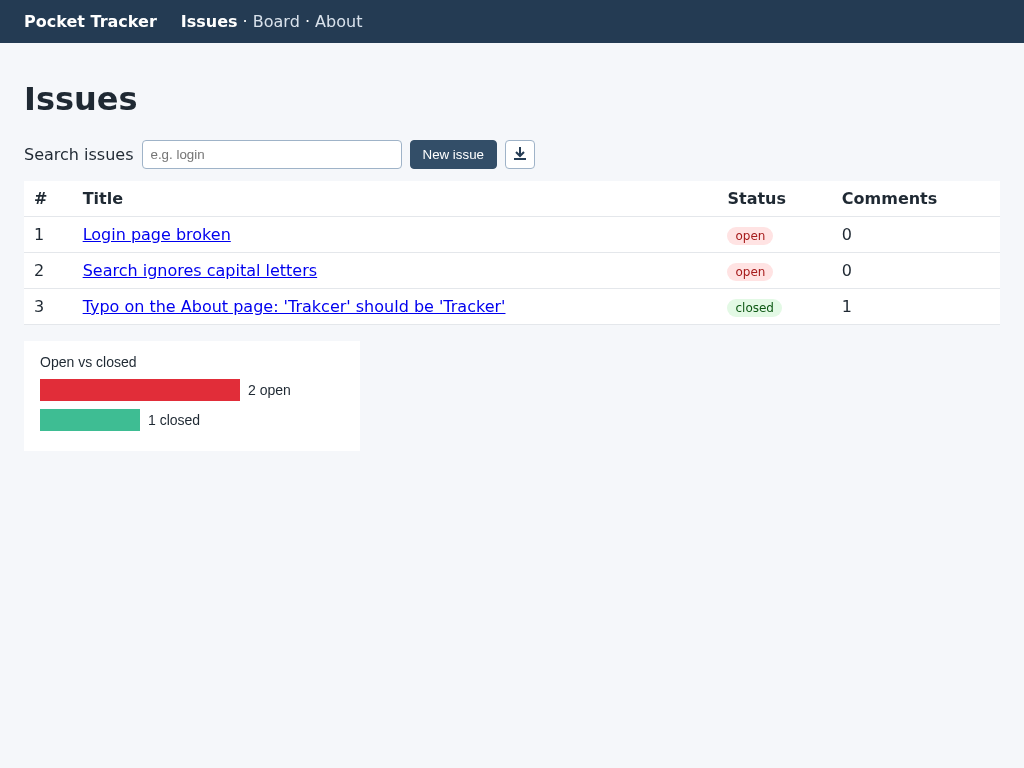

In [3]:
from PIL import Image
from IPython.display import display

img = Image.open(png_path)
print("size:", img.size, "mode:", img.mode)
display(img)

An image is not tokenized like text. Its cost depends on its **pixel size**, not on the file size or what is drawn. Claude's docs give `tokens = ceil(width/28) * ceil(height/28)` for current models. Other vendors use other formulas (lesson 10 compares them). Notice that the empty bottom half of the page costs the same as the table.

In [4]:
import math

def claude_image_tokens(width, height):
    return math.ceil(width / 28) * math.ceil(height / 28)

w, h = img.size
screenshot_tokens = claude_image_tokens(w, h)
print(f"{w}x{h} screenshot ≈ {screenshot_tokens} tokens")

1024x768 screenshot ≈ 1036 tokens


### 4. The accessibility tree: an aria snapshot
Playwright's `aria_snapshot()` writes the accessibility tree as YAML: one line per element, with its role (`link`, `button`, `row`) and its accessible name in quotes. Layout, colours and CSS are gone.

In [5]:
print(aria_text[:900])
aria_tokens = len(enc.encode(aria_text))
print("...\naria snapshot ≈", aria_tokens, "tokens")

- banner:
  - strong: Pocket Tracker
  - navigation "Main":
    - link "Issues":
      - /url: /issues
    - text: ·
    - link "Board":
      - /url: /board
    - text: ·
    - link "About":
      - /url: /about
- main:
  - heading "Issues" [level=1]
  - text: Search issues
  - searchbox "Search issues"
  - button "New issue"
  - button:
    - img
  - table:
    - rowgroup:
      - row "# Title Status Comments":
        - columnheader "#"
        - columnheader "Title"
        - columnheader "Status"
        - columnheader "Comments"
    - rowgroup:
      - row "1 Login page broken open 0":
        - cell "1"
        - cell "Login page broken":
          - link "Login page broken":
            - /url: /issues/1
        - cell "open"
        - cell "0"
      - row "2 Search ignores capital letters open 0":
        - cell "2"
        - cell "Search ignores capital letters":
          - li
...
aria snapshot ≈ 382 tokens


### 5. The DOM: raw HTML
The DOM is everything the browser built: the same text, plus tags, attributes, a `<style>` block and a `<script>`. Most of it is there for the browser, not for an agent deciding what to click.

In [6]:
print(html_text[:500])
html_tokens = len(enc.encode(html_text))
print("...\nraw HTML ≈", html_tokens, "tokens")

<!DOCTYPE html><html lang="en"><head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Issues · Pocket Tracker</title>
<style>
  body { font-family: system-ui, sans-serif; margin: 0; color: #1f2933; background: #f5f7fa; }
  header { display: flex; align-items: center; gap: 24px; padding: 12px 24px; background: #243b53; color: #fff; }
  header a { color: #d9e2ec; text-decoration: none; }
  header a[aria-current="page"] { color: #fff; font-weight: 
...
raw HTML ≈ 1166 tokens


### 6. Cost per step and per run
Every step of an agent loop sends a fresh observation. A short task of 30 steps pays for 30 of them, before counting the conversation history the model also rereads.

In [7]:
costs = {"screenshot": screenshot_tokens, "aria snapshot": aria_tokens, "raw HTML": html_tokens}
steps = 30
print(f"{'observation':14} {'per step':>9} {'30 steps':>9}")
for name, tokens in costs.items():
    print(f"{name:14} {tokens:>9} {tokens * steps:>9}")

observation     per step  30 steps
screenshot          1036     31080
aria snapshot        382     11460
raw HTML            1166     34980


On this tiny page the aria snapshot costs about a third of the other two. The screenshot cost is fixed by the viewport; the text costs grow with the page.

### 7. What each one can see
Size is half the story. The page has three traps: a chart drawn on a `<canvas>`, a hidden admin button (`display: none`), and an icon-only download button with no label. Let us search each text observation for them.

In [8]:
probes = {
    "issue title 'Search ignores capital letters'": "Search ignores capital letters",
    "chart label '2 open' (drawn on a canvas)": "2 open",
    "hidden 'Delete all issues' button": "Delete all issues",
    "a name for the download icon": "Download",
}
print(f"{'probe':48} {'aria':>5} {'html':>5}")
for label, text in probes.items():
    print(f"{label:48} {str(text in aria_text):>5} {str(text in html_text):>5}")

probe                                             aria  html
issue title 'Search ignores capital letters'      True  True
chart label '2 open' (drawn on a canvas)         False  True
hidden 'Delete all issues' button                False  True
a name for the download icon                     False False


Compare with the screenshot above, checked by eye: the title and "2 open" are visible, the admin button is not, and the icon shows an arrow but no word.
- The **canvas** chart is missing from the aria snapshot. "2 open" is in the HTML only inside the `<script>` that draws it: an agent would have to read JavaScript to learn what the user sees at a glance.
- The **hidden** button is in the DOM but not in the aria snapshot or the picture. An agent reading HTML might try to click something no user can see.
- The **unlabelled icon** is a bare `button:` with an `img` in the aria snapshot. Only pixels hint at what it does.

In [9]:
print([line.strip() for line in aria_text.splitlines() if line.strip().startswith(("- button", "- img"))])

['- button "New issue"', '- button:', '- img']


### 8. Grow the page: 50 issues
Pocket Tracker will hold more than three issues. Text observations grow by roughly one row per issue; the screenshot stays the same size but shows only about 15 rows, so the agent must scroll and take more screenshots. Measure one row in each text form, then estimate a 50-issue page.

In [10]:
import re

html_row = re.search(r'<tr data-issue-id="2">.*?</tr>', html_text, re.S).group()
aria_lines = aria_text.splitlines()
start = next(i for i, l in enumerate(aria_lines) if '- row "2 ' in l)
aria_row = "\n".join(aria_lines[start:start + 7])       # the row and its 6 child lines
print(aria_row)

per_row = {"aria snapshot": len(enc.encode(aria_row)), "raw HTML": len(enc.encode(html_row))}
print("tokens per issue row:", per_row)

      - row "2 Search ignores capital letters open 0":
        - cell "2"
        - cell "Search ignores capital letters":
          - link "Search ignores capital letters":
            - /url: /issues/2
        - cell "open"
        - cell "0"
tokens per issue row: {'aria snapshot': 59, 'raw HTML': 55}


Now the estimate. For the screenshot we assume about 15 visible rows per 1024x768 screen, so 50 issues need 4 screenshots to see them all.

In [11]:
n_issues = 50
estimate = {name: costs[name] + per_row[name] * (n_issues - 3) for name in per_row}
estimate["screenshot"] = math.ceil(n_issues / 15) * screenshot_tokens
for name, tokens in sorted(estimate.items(), key=lambda kv: kv[1]):
    print(f"{name:14} ≈ {tokens:>6} tokens to see all {n_issues} issues")

aria snapshot  ≈   3155 tokens to see all 50 issues
raw HTML       ≈   3751 tokens to see all 50 issues
screenshot     ≈   4144 tokens to see all 50 issues


Per row the two text forms cost about the same here, because the aria snapshot repeats each title in the row, the cell and the link. The HTML gap comes from its fixed overhead (the `<style>` and `<script>`). Real pages are heavier: framework markup, long class names and inline scripts often make raw HTML many times larger, while the aria snapshot keeps only what a user can perceive.

## At work
- Browser tools that coding agents use default to the accessibility tree: Playwright MCP sends accessibility snapshots by default and turns on screenshots only with `--caps=vision`; its README points to Playwright CLI + skills as even more token-efficient → lessons 08 and 27a.
- Screenshots cost about 1,000–1,800 input tokens each in Claude's docs, which also advise at most 20 images per request or downscaling; pruning old images and prompt caching are the cost levers → lessons 10 and 32a.
- What the accessibility tree misses breaks real agents: canvas, iframes, shadow DOM and native `alert()` dialogs (Anthropic's harness post notes Puppeteer could not see browser-native alert modals) → lessons 08 and 12.
- Teams use the aria snapshot as the main loop and add a screenshot only when needed, because a recorded screenshot loop stores base64 images and grows fast → lessons 12 and 13.

## What just happened
- You loaded one page as a **screenshot**, an **aria snapshot** and raw **DOM** HTML, all recorded once by Playwright.
- You counted text tokens with `tiktoken` and estimated image tokens from pixel size with Claude's formula.
- On this page: screenshot ≈ 1,036 tokens, aria ≈ 380, HTML ≈ 1,170 per step; at 50 issues aria still costs the least.
- Each form hides something: canvas text is missing from the aria tree (and buried in a script in the HTML), a hidden button is DOM-only, an unlabelled icon has no name in any text form.
- Text costs grow with the page; screenshot cost is fixed per screen, but big pages need more screens.

## Common mistakes
Sending raw HTML as the observation. Say the harness allows 3,500 tokens per observation. The 50-issue page as HTML does not fit:

In [12]:
budget = 3500
assert estimate["raw HTML"] <= budget, f"raw HTML needs {estimate['raw HTML']} tokens, budget is {budget}"

AssertionError: raw HTML needs 3751 tokens, budget is 3500

Fix: send the aria snapshot, which keeps the roles and names the agent needs to act.

In [13]:
assert estimate["aria snapshot"] <= budget
print(f"aria snapshot fits: {estimate['aria snapshot']} <= {budget}")

aria snapshot fits: 3155 <= 3500


Second mistake: estimating image cost from the file. Counting the base64 text of the PNG as if it were text gives a wildly wrong number; the model is billed by pixel size.

In [14]:
import base64
b64 = base64.b64encode(png_path.read_bytes()).decode()
print("base64 counted as text:", len(enc.encode(b64)), "tokens  (wrong)")
print("pixel formula         :", screenshot_tokens, "tokens  (right)")

base64 counted as text: 33620 tokens  (wrong)
pixel formula         : 1036 tokens  (right)


## Try it
Agents often downscale screenshots to save tokens. Use Pillow's `img.resize(...)` to make the screenshot 1280x960 and 512x384 (same 4:3 shape). For each size, print its token estimate with `claude_image_tokens` and how many aria snapshots of this page would cost the same. Then look at the 512x384 image: can you still read the issue titles?

In [15]:
# your code here

## Key terms
- **screenshot** — the page as pixels; a vision model's observation, costed by image size, not by content.
- **accessibility tree** — the roles and names of a page's elements as assistive tech sees them; Playwright prints it as an aria snapshot.
- **aria snapshot** — Playwright's YAML text form of the accessibility tree (`page.aria_snapshot()`).
- **DOM** — the browser's full model of the page; its raw HTML includes tags, attributes, styles and scripts.
- **observation cost** — the tokens one observation adds to every model call, multiplied by the steps in a run.